data:
   animal_name  hair  feathers  eggs  milk  airborne  aquatic  predator  \
0    aardvark     1         0     0     1         0        0         1   
1    antelope     1         0     0     1         0        0         0   
2        bass     0         0     1     0         0        1         1   
3        bear     1         0     0     1         0        0         1   
4        boar     1         0     0     1         0        0         1   

   toothed  backbone  breathes  venomous  fins  legs  tail  domestic  catsize  \
0        1         1         1         0     0     4     0         0        1   
1        1         1         1         0     0     4     1         0        1   
2        1         1         0         0     1     0     1         0        0   
3        1         1         1         0     0     4     0         0        1   
4        1         1         1         0     0     4     1         0        1   

   class_type  
0           1  
1           1  
2           4

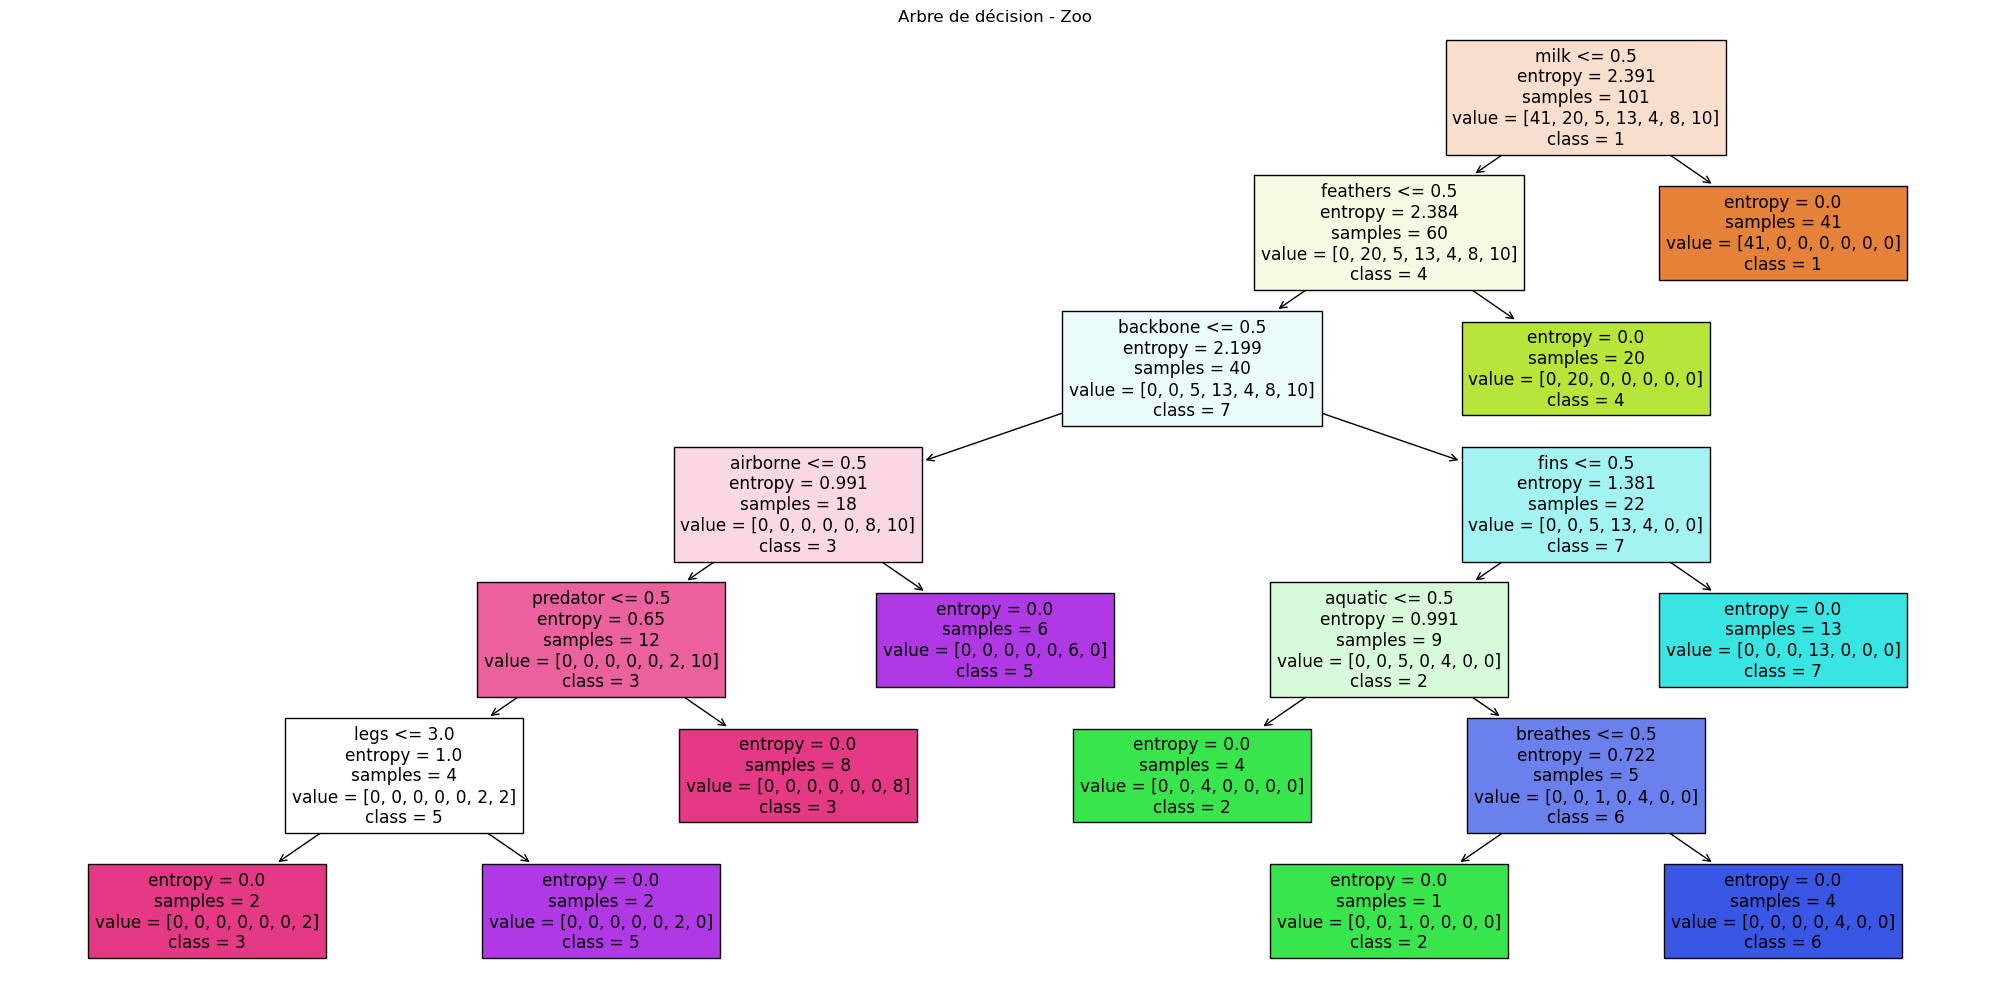

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# Charger directement le fichier zoo.csv (plus besoin de boîte de dialogue)
zoo_data = pd.read_csv('zoo.csv')

print("data:\n", zoo_data.head())

X = zoo_data.drop(columns=['animal_name', 'class_type'])  
y = zoo_data['class_type'] 

# Entraîner le modèle avec l'entropie
clf = DecisionTreeClassifier(criterion='entropy')
clf.fit(X, y)

class_names = y.unique().astype(str)

# Dessiner l'arbre de décision
plt.figure(figsize=(20, 10))
tree.plot_tree(clf, feature_names=X.columns.tolist(), class_names=class_names.tolist(), filled=True)
plt.title("Arbre de décision - Zoo")
plt.tight_layout()
plt.show()

In [2]:
def poser_question(df, question, reponse):
    return df[df[question] == reponse]

def jouer():
    print("\nBienvenue dans le jeu de la devinette !")
    print("Pensez à un animal et je vais essayer de deviner.")
    
    df_filtre = zoo_data.copy()
    questions_posees = []

    while df_filtre.shape[0] > 1:
        question_posee = False
        for colonne in df_filtre.columns[1:-1]:  # ignorer animal_name et class_type
            if df_filtre[colonne].nunique() == 2 and colonne not in questions_posees:
                print(f"{colonne.replace('_', ' ').capitalize()} ? (oui/non)")  
                reponse = input("-> ").strip().lower()  
                if reponse not in ['oui', 'non']:  
                    print("Réponse invalide. Je continue...")
                    continue
                
                val = 1 if reponse == 'oui' else 0  
                df_filtre = poser_question(df_filtre, colonne, val) 
                questions_posees.append(colonne)
                question_posee = True

                if df_filtre.shape[0] == 1:
                    animal = df_filtre['animal_name'].values[0]
                    print(f"\nJe pense que vous avez choisi : {animal}")
                    return
                break
        
        if not question_posee:
            break

    if df_filtre.shape[0] == 1:
        animal = df_filtre['animal_name'].values[0]
        print(f"\nJe pense que vous avez choisi : {animal}")
    elif df_filtre.shape[0] == 0:
        print("\nAucun animal ne correspond à vos réponses !")
    else:
        animaux = df_filtre['animal_name'].values.tolist()
        print(f"\nTrop d'animaux possibles, je ne peux pas deviner avec certitude !")
        print(f"Candidats possibles : {animaux}")

jouer()


Bienvenue dans le jeu de la devinette !
Pensez à un animal et je vais essayer de deviner.
Hair ? (oui/non)
Eggs ? (oui/non)
Milk ? (oui/non)
Venomous ? (oui/non)

Trop d'animaux possibles, je ne peux pas deviner avec certitude !
Candidats possibles : ['housefly', 'moth']
